In [107]:
import os
import pandas as pd
import numpy as np
import matplotlib as plt
import networkx as nx
import mip

BUILDING_NAME = "Edificio2.csv"

ASCENDING_SPEED = 1.0
DESCENDING_SPEED = 2.0
HORIZONTAL_SPEED = 1.5

ASCENDING_ENERGY = 50
DESCENDING_ENERGY = 5
HORIZONTAL_ENERGY = 10

X_BASE_RANGE = range(-8, 6) if "Edificio1.csv" == BUILDING_NAME else range(-10, 11)
Y_BASE_RANGE = range(-17, -14) if "Edificio1.csv" == BUILDING_NAME else range(-31, -29)
Z_BASE = 0

MAX_SECONDS = 7200 if "Edificio1.csv"==BUILDING_NAME else 1500

BATTERY_CAPACITY = 3600 if "Edificio1.csv" == BUILDING_NAME else 21600  # 1 Wh is 3600 J

Y_ENTRY_POINT = -12.5 if "Edificio1.csv" == BUILDING_NAME else -20.0

# Reading CSV and creating pairs


In [108]:
# loading building csv data

nodes = pd.read_csv(BUILDING_NAME)

# Creating Bases and entry points

In [109]:
nodes["is_base"] = False
nodes["is_entry_point"] = nodes["y"] <= Y_ENTRY_POINT

# Genero tutte le basi candidate come prima
bases = []
for x in X_BASE_RANGE:
    for y in Y_BASE_RANGE:
        bases.append(
            {"x": x, "y": y, "z": Z_BASE, "is_base": True, "is_entry_point": False}
        )

bases_df = pd.DataFrame(bases)

# Calcolo del centroide sui nodi di servizio
centroid_x = nodes["x"].mean()
centroid_y = nodes["y"].mean()

# Seleziono la base candidata più vicina al centroide (distanza euclidea su x,y)
bases_df["dist_centroid"] = np.hypot(
    bases_df["x"] - centroid_x, bases_df["y"] - centroid_y
)
nearest_idx = bases_df["dist_centroid"].idxmin()
selected_base = bases_df.loc[[nearest_idx]].drop(columns=["dist_centroid"])

# Mantengo solo i nodi di servizio + la base più vicina al centroide
building = pd.concat([nodes, selected_base], ignore_index=True)
active_base = building.index[-1]  # Definisco l'indice della base selezionata

building.to_csv("building.csv", index=False)
print(
    f"Base scelta (indice {active_base}): "
    f"(x={selected_base.iloc[0]['x']}, y={selected_base.iloc[0]['y']}, z={Z_BASE})"
)

Base scelta (indice 696): (x=-3, y=-30, z=0)


# Merging nodes to create pairs

In [110]:
building.index += 1
active_base = building.index[
    building["is_base"]
].item()  # Aggiorno active_base dopo lo shift
# Adding is_base and is_entry_point columns

# generating all possible pairs of points (edges)
nodes_pairs = (
    building.rename_axis("source_node")
    .reset_index()
    .merge(building.rename_axis("target_node").reset_index(), how="cross")
)

# removing self-self pairs
nodes_pairs = nodes_pairs[
    nodes_pairs["source_node"] != nodes_pairs["target_node"]
]  # keeping only pairs with different points

In [111]:
first_point_cols = ["x_x", "y_x", "z_x"]
second_point_cols = ["x_y", "y_y", "z_y"]
diff_cols = ["dx", "dy", "dz"]

# Computing distances 

In [112]:
# function to determine if two points are connected based on distance and coordinate deltas


def process_connections(dataframe):
    # distances and deltas on coordinates
    dataframe[diff_cols] = (
        dataframe[second_point_cols].values - dataframe[first_point_cols].values
    )
    dataframe["euclidean_distance"] = np.sqrt(
        (dataframe[diff_cols] ** 2).sum(axis=1)
    )  # axis=1 sum on columns

    # conditions near and tunnel
    condition_near = dataframe["euclidean_distance"] <= 4.0

    condition_tunnel = (
        ((dataframe["dx"].abs() <= 0.5) & (dataframe["dy"].abs() <= 0.5))
        | ((dataframe["dy"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
        | ((dataframe["dx"].abs() <= 0.5) & (dataframe["dz"].abs() <= 0.5))
    )

    condition_tunnel_and_not_far = (
        dataframe["euclidean_distance"] <= 11.0
    ) & condition_tunnel

    # if the arc is from base to entry point or viceversa
    condition_base_to_entry_point = (
        (dataframe["is_base_x"]) & (dataframe["is_entry_point_y"])
    ) | ((dataframe["is_base_y"]) & (dataframe["is_entry_point_x"]))

    # l'unica connessione ammessa è base <-> entry point
    condition_involves_base = dataframe["is_base_x"] | dataframe["is_base_y"]

    # Gli archi tra nodi griglia usano le regole di distanza (near/tunnel)
    # Gli archi con basi usano SOLO la regola base <-> entry point
    dataframe["are_connected"] = (
        (condition_near & ~condition_involves_base)
        | (condition_tunnel_and_not_far & ~condition_involves_base)
        | condition_base_to_entry_point
    )
    return dataframe

In [113]:
nodes_pairs = process_connections(nodes_pairs)

nodes_pairs.to_csv("pairs.csv", index=False)

nodes_pairs.head()

,source_node,x_x,y_x,z_x,is_base_x,is_entry_point_x,target_node,x_y,y_y,z_y,is_base_y,is_entry_point_y,dx,dy,dz,euclidean_distance,are_connected
1,1,-15.7277,-18.288,79.3699,False,False,2,-16.9469,-14.8742,79.3699,False,False,-1.2192,3.4138,0.0,3.624980,True
2,1,-15.7277,-18.288,79.3699,False,False,3,-16.9469,-7.2542,79.3699,False,False,-1.2192,11.0338,0.0,11.100955,False
3,1,-15.7277,-18.288,79.3699,False,False,4,-19.1110,-7.2542,79.3699,False,False,-3.3833,11.0338,0.0,11.540861,False
4,1,-15.7277,-18.288,79.3699,False,False,5,-20.7264,-5.9131,79.3699,False,False,-4.9987,12.3749,0.0,13.346353,False
5,1,-15.7277,-18.288,79.3699,False,False,6,-20.7264,-3.4138,79.3699,False,False,-4.9987,14.8742,0.0,15.691680,False


In [114]:
# computing vertical distances on z and distances on horizontal plane x,y
nodes_pairs["d_horizontal"] = np.sqrt(nodes_pairs["dx"] ** 2 + nodes_pairs["dy"] ** 2)
nodes_pairs["d_vertical"] = nodes_pairs["dz"]

# dropping columns that are not useful anymore
nodes_pairs.drop(columns=["dx", "dy", "dz"], inplace=True)
nodes_pairs.drop(columns=["x_x", "y_x", "z_x", "x_y", "y_y", "z_y"], inplace=True)

# keeping only connected pairs
nodes_pairs = nodes_pairs[nodes_pairs["are_connected"] == True]
nodes_pairs.drop(columns=["are_connected"], inplace=True)

nodes_pairs.head(5)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,euclidean_distance,d_horizontal,d_vertical
1,1,False,False,2,False,False,3.62498,3.62498,0.0000
40,1,False,False,41,False,False,3.84050,3.84050,0.0000
41,1,False,False,42,False,False,4.38910,0.00000,-4.3891
82,1,False,False,83,False,False,9.87550,0.00000,-9.8755
653,1,False,False,654,False,False,7.74190,7.74190,0.0000


# Function for time travel

In [115]:
# finding rows corresponding to different movement types

d_horizontal = nodes_pairs["d_horizontal"]
d_vertical = nodes_pairs["d_vertical"]
rows_horizontal = d_vertical == 0
rows_ascending = (d_horizontal == 0) & (d_vertical > 0)
rows_descending = (d_horizontal == 0) & (d_vertical < 0)
rows_oblique_ascending = (d_horizontal != 0) & (d_vertical > 0)
rows_oblique_descending = (d_horizontal != 0) & (d_vertical < 0)

In [116]:
# function for time travel based on movement types and speeds


def compute_time_travel(dataframe):
    dataframe.loc[rows_horizontal, "time_travel"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] / HORIZONTAL_SPEED
    )

    dataframe.loc[rows_ascending, "time_travel"] = (
        dataframe.loc[rows_ascending, "d_vertical"] / ASCENDING_SPEED
    )
    dataframe.loc[rows_descending, "time_travel"] = (
        -dataframe.loc[rows_descending, "d_vertical"] / DESCENDING_SPEED
    )

    dataframe.loc[rows_oblique_ascending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] / HORIZONTAL_SPEED,
        dataframe.loc[rows_oblique_ascending, "d_vertical"] / ASCENDING_SPEED,
    )

    dataframe.loc[rows_oblique_descending, "time_travel"] = np.maximum(
        dataframe.loc[rows_oblique_descending, "d_horizontal"] / HORIZONTAL_SPEED,
        -dataframe.loc[rows_oblique_descending, "d_vertical"] / DESCENDING_SPEED,
    )
    return dataframe

# Function for energy consumption


In [117]:
# function for energy cost based on movement types and energy consumption rates


def compute_energy_cost(dataframe):
    dataframe.loc[rows_horizontal, "energy_consumption"] = (
        dataframe.loc[rows_horizontal, "d_horizontal"] * HORIZONTAL_ENERGY
    )

    dataframe.loc[rows_ascending, "energy_consumption"] = (
        dataframe.loc[rows_ascending, "d_vertical"] * ASCENDING_ENERGY
    )
    dataframe.loc[rows_descending, "energy_consumption"] = (
        -dataframe.loc[rows_descending, "d_vertical"] * DESCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_ascending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_ascending, "d_horizontal"] * HORIZONTAL_ENERGY
        + dataframe.loc[rows_oblique_ascending, "d_vertical"] * ASCENDING_ENERGY
    )

    dataframe.loc[rows_oblique_descending, "energy_consumption"] = (
        dataframe.loc[rows_oblique_descending, "d_horizontal"] * HORIZONTAL_ENERGY
        + -dataframe.loc[rows_oblique_descending, "d_vertical"] * DESCENDING_ENERGY
    )
    return dataframe

# Actually computing energy and time costs for arcs

In [118]:
# computing time travel and energy cost for each pair (edges)

nodes_pairs = compute_time_travel(nodes_pairs)

nodes_pairs = compute_energy_cost(nodes_pairs)

# rounding to 2 decimal places
nodes_pairs["time_travel"] = nodes_pairs["time_travel"].round(2)
nodes_pairs["energy_consumption"] = nodes_pairs["energy_consumption"].round(2)

nodes_pairs.drop(
    columns=["d_horizontal", "d_vertical", "euclidean_distance"], inplace=True
)

nodes_pairs.head(10)

,source_node,is_base_x,is_entry_point_x,target_node,is_base_y,is_entry_point_y,time_travel,energy_consumption
1,1,False,False,2,False,False,2.42,36.25
40,1,False,False,41,False,False,2.56,38.40
41,1,False,False,42,False,False,2.19,21.95
82,1,False,False,83,False,False,4.94,49.38
653,1,False,False,654,False,False,5.16,77.42
697,2,False,False,1,False,False,2.42,36.25
699,2,False,False,3,False,False,5.08,76.20
739,2,False,False,43,False,False,2.19,21.95
780,2,False,False,84,False,False,4.94,49.38
1395,3,False,False,2,False,False,5.08,76.20


In [119]:

# # Pruning degli archi: manteniamo gli archi più corti sia in uscita che in entrata per garantire la connettività
# k_keep = 50

# # Archi migliori in uscita (per garantire out-degree >= 1)
# out_edges = nodes_pairs.sort_values("time_travel").groupby("source_node").head(k_keep)

# # Archi migliori in entrata (per garantire in-degree >= 1)
# in_edges = nodes_pairs.sort_values("time_travel").groupby("target_node").head(k_keep)

# base_arcs_all = nodes_pairs[
#     (nodes_pairs["is_base_x"] & nodes_pairs["is_entry_point_y"])
#     | (nodes_pairs["is_base_y"] & nodes_pairs["is_entry_point_x"])
# ]

# # Unione degli archi per evitare nodi isolati + archi base preservati
# nodes_pairs = pd.concat([out_edges, in_edges, base_arcs_all]).drop_duplicates()

# print(
#     f"Archi base ↔ entry_point preservati: {len(base_arcs_all)} totali"
# )
# print(f"Pruning completato. Archi rimanenti: {len(nodes_pairs)}")

# Creating Graph with Networkx


In [120]:
# creating directed graph G from the dataframe of edges with costs

G = nx.from_pandas_edgelist(
    nodes_pairs,  # dataframe containing edges
    source="source_node",  # indicating the start of the edge
    target="target_node",  # indicating the end of the edge
    edge_attr=["time_travel", "energy_consumption"],  # edge costs
    create_using=nx.DiGraph(),  # creating an oriented graph
)

# nx.draw_networkx(G, node_size=50, font_size=8)

# Clustering per viaggi (zone connesse base↔nodi)

In [ ]:
from scipy.cluster.vq import kmeans2

if "Edificio1" in BUILDING_NAME:
    K_WANTED=1
    print("edifioc1")
else:
    K_WANTED = 4
MAX_CLUSTER_SIZE = 220

service_nodes = building[building["is_base"] == False].index.tolist()
reachable_from_base = nx.single_source_dijkstra_path_length(
    G, active_base, weight="energy_consumption"
)
reachable_to_base = nx.single_source_dijkstra_path_length(
    G.reverse(), active_base, weight="energy_consumption"
)
valid_nodes = [
    n for n in service_nodes if n in reachable_from_base and n in reachable_to_base
]
np.random.seed(90)  # Fissiamo il seed per rendere il clustering deterministico
# 2. K-means Puro: Ogni nodo appartiene a un solo gruppo geografico
coords_array = building.loc[valid_nodes, ["x", "y", "z"]].to_numpy()
centroidi, labels = kmeans2(coords_array, K_WANTED, minit="points", iter=30)

trips = [[] for _ in range(K_WANTED)]
for idx, label in enumerate(labels):
    trips[label].append(valid_nodes[idx])

# 3. Bilanciamento dimensioni (Split dei troppo grandi)
final_trips = []
for t in trips:
    if len(t) > MAX_CLUSTER_SIZE:
        final_trips.append(t[: len(t) // 2])
        final_trips.append(t[len(t) // 2 :])
    elif t:
        final_trips.append(t)

trips = final_trips
print(f"Cluster geografici creati: {len(trips)}")
print("Nodi per cluster:", [len(t) for t in trips])
TRIPS_READY = True

Cluster geografici creati: 4
Nodi per cluster: [218, 158, 158, 162]


In [122]:
def diagnose_cluster(cluster_idx, t_nodes, base_node, G_full, capacity):
    """
    Diagnostica dettagliata di un cluster:
    - Verifica connettività dalla base
    - Verifica raggiungibilità dei nodi tra loro
    - Stima energetica realistica per un tour TSP sommando i costi degli archi
    """

    diag = {
        "cluster_idx": cluster_idx,
        "num_nodes": len(t_nodes),
        "reachable_from_base": [],
        "can_return_to_base": [],
        "unreachable_nodes": [],
        "issues": [],
        "warnings": [],
        "total_min_energy_required": 0,
        "max_single_ar": 0,
    }

    # Calcola distanze minime dalla base a tutti i nodi (via Dijkstra)
    dist_from_base = nx.single_source_dijkstra_path_length(
        G_full, base_node, weight="energy_consumption"
    )

    # Calcola distanze minime dai nodi alla base
    dist_to_base = {}
    for node in t_nodes:
        try:
            path_length = nx.single_source_dijkstra_path_length(
                G_full, node, weight="energy_consumption"
            )
            if base_node in path_length:
                dist_to_base[node] = path_length[base_node]
        except:
            pass

    min_incoming_cost = (
        {}
    )  # Costo minimo di ingresso per ogni nodo (da altri nodi del cluster)
    min_outgoing_cost = (
        {}
    )  # Costo minimo di uscita per ogni nodo (verso altri nodi del cluster)
    max_single_ar = 0  # Il massimo A/R singolo per qualsiasi nodo

    # Costruisci set di nodi cluster per ricerche veloci
    N_cluster_set = set([base_node] + t_nodes)

    for node in t_nodes:
        # Controlla raggiungibilità dalla base
        if node in dist_from_base:
            diag["reachable_from_base"].append(node)
            energy_from_base = dist_from_base[node]
        else:
            diag["unreachable_nodes"].append(node)
            diag["issues"].append(f"Nodo {node}: NON raggiungibile dalla base")
            continue

        # Controlla se può tornare alla base
        if node in dist_to_base:
            diag["can_return_to_base"].append(node)
            energy_to_base = dist_to_base[node]
        else:
            diag["issues"].append(f"Nodo {node}: NON può tornare alla base")
            continue

        # Verifica vincolo energetico minimo (A/R singolo)
        min_round_trip = energy_from_base + energy_to_base
        max_single_ar = max(max_single_ar, min_round_trip)

        if min_round_trip > capacity:
            diag["warnings"].append(
                f"Nodo {node}: Viaggio A/R singolo ({min_round_trip:.1f}J) > Batteria ({capacity}J)"
            )

    # STIMA DELL'ENERGIA PER UN UNICO TOUR TSP:
    # Per ogni nodo nel cluster, trova il costo minimo degli archi di ingresso/uscita
    # dai/verso altri nodi nel cluster (non dalla base!)
    for node in t_nodes:
        # Costi di ingresso: archi (i, node) dove i è nel cluster
        incoming_costs = [
            G_full[i][node]["energy_consumption"]
            for i in N_cluster_set
            if i != node and G_full.has_edge(i, node)
        ]
        min_incoming_cost[node] = (
            min(incoming_costs) if incoming_costs else float("inf")
        )

        # Costi di uscita: archi (node, j) dove j è nel cluster
        outgoing_costs = [
            G_full[node][j]["energy_consumption"]
            for j in N_cluster_set
            if j != node and G_full.has_edge(node, j)
        ]
        min_outgoing_cost[node] = (
            min(outgoing_costs) if outgoing_costs else float("inf")
        )

    # Stima tour TSP: per un tour che visita tutti i nodi una volta,
    # approssimiamo come la somma dei costi minimi di ingresso per ogni nodo
    # (questo rappresenta il costo di "raggiungerlo" e poi continuare il tour)
    # PIÙ il costo di ritorno alla base dall'ultimo nodo
    valid_incoming = [c for c in min_incoming_cost.values() if c != float("inf")]
    valid_outgoing = [c for c in min_outgoing_cost.values() if c != float("inf")]

    if valid_incoming and valid_outgoing:
        # Stima pessimistica: somma dei costi minimi di ingresso + uscita
        # Questo rappresenta il "ciclo" per visitare ogni nodo
        estimate_tour = sum(valid_incoming) + max(valid_outgoing)
    else:
        estimate_tour = 0

    diag["total_min_energy_required"] = estimate_tour
    diag["max_single_ar"] = max_single_ar

    # Verifica connettività interna tra nodi del cluster
    # Controlla se tutti i nodi raggiungibili sono interconnessi
    for start_node in t_nodes:
        try:
            local_reach = nx.single_source_dijkstra_path_length(
                G_full, start_node, weight="energy_consumption"
            )
            for target_node in t_nodes:
                if target_node != start_node and target_node not in local_reach:
                    diag["issues"].append(
                        f"Connettività: Nodo {start_node} non raggiunge Nodo {target_node}"
                    )
                    break
        except:
            pass

    return diag


# Esegui diagnostica per ogni cluster
cluster_diagnostics = []
feasible_clusters = []
infeasible_clusters = []

for idx, t_nodes in enumerate(trips, start=1):
    diag = diagnose_cluster(idx, t_nodes, active_base, G, BATTERY_CAPACITY)
    cluster_diagnostics.append(diag)

    # Stampa risultati
    print(f"Cluster {idx}: {len(t_nodes)} nodi")
    print(
        f"  Base -> Nodi raggiungibili: {len(diag['reachable_from_base'])}/{len(t_nodes)}"
    )
    print(
        f"  Nodi -> Base raggiungibili: {len(diag['can_return_to_base'])}/{len(t_nodes)}"
    )

    if diag["unreachable_nodes"]:
        print(f"  ❌ Nodi non raggiungibili: {diag['unreachable_nodes']}")

    if diag["issues"]:
        print(f"  ⚠️  PROBLEMI RILEVATI:")
        for issue in diag["issues"]:
            print(f"     - {issue}")
        infeasible_clusters.append(idx)
    else:
        print(f"  ✅ Cluster connesso e raggiungibile dalla base")
        feasible_clusters.append(idx)

    if diag["warnings"]:
        print(f"  ⚠️  AVVERTIMENTI:")
        for warning in diag["warnings"]:
            print(f"     - {warning}")

    print(f"  📊 Stima ENERGIA PER TOUR TSP (sommando i costi degli archi):")
    print(f"     - Max A/R singolo nodo: {diag.get('max_single_ar', 0):.1f}J")
    print(f"     - Stima tour totale: {diag['total_min_energy_required']:.1f}J")
    print(f"     - Capacità batteria: {BATTERY_CAPACITY}J")
    if diag["total_min_energy_required"] > BATTERY_CAPACITY:
        ratio = diag["total_min_energy_required"] / BATTERY_CAPACITY
        print(f"     ⚠️  TOUR NON FATTIBILE IN UNA CARICA ({ratio:.1f}x capacità)")
    else:
        print(f"     ✅ Tour possibile in una carica")
    print()

print(f"\n{'='*70}")
print(f"RIEPILOGO DIAGNOSTICA")
print(f"{'='*70}")
print(f"✅ Cluster FEASIBLE (connessi e raggiungibili): {feasible_clusters}")
print(f"❌ Cluster INFEASIBLE (problemi di connettività): {infeasible_clusters}")
print(f"{'='*70}\n")

Cluster 1: 207 nodi
  Base -> Nodi raggiungibili: 207/207
  Nodi -> Base raggiungibili: 207/207
  ✅ Cluster connesso e raggiungibile dalla base
  📊 Stima ENERGIA PER TOUR TSP (sommando i costi degli archi):
     - Max A/R singolo nodo: 5719.3J
     - Stima tour totale: 5099.9J
     - Capacità batteria: 21600J
     ✅ Tour possibile in una carica

Cluster 2: 181 nodi
  Base -> Nodi raggiungibili: 181/181
  Nodi -> Base raggiungibili: 181/181
  ✅ Cluster connesso e raggiungibile dalla base
  📊 Stima ENERGIA PER TOUR TSP (sommando i costi degli archi):
     - Max A/R singolo nodo: 2934.8J
     - Stima tour totale: 4251.4J
     - Capacità batteria: 21600J
     ✅ Tour possibile in una carica

Cluster 3: 138 nodi
  Base -> Nodi raggiungibili: 138/138
  Nodi -> Base raggiungibili: 138/138
  ✅ Cluster connesso e raggiungibile dalla base
  📊 Stima ENERGIA PER TOUR TSP (sommando i costi degli archi):
     - Max A/R singolo nodo: 5288.5J
     - Stima tour totale: 4055.7J
     - Capacità batteria: 

# MODELLO MIP

In [123]:
# LOOP SU TUTTI I CLUSTER
# Per ogni cluster risolviamo un MIP separato
# Usa il modello SCF che funzionava su Edificio1
# Ogni viaggio = 1 sola partenza dalla base → 1 ciclo base→...→base

import math

results = []  # Risultati di ottimizzazione per ogni cluster

for cluster_idx, t_nodes in enumerate(trips, start=1):
    print(f"\n{'='*70}")
    print(f"CLUSTER {cluster_idx}: {len(t_nodes)} nodi di servizio")
    print(f"{'='*70}")

    # ===============================================================
    # STEP 1: CREIAMO I SET PER QUESTO CLUSTER
    # Aggiungiamo nodi intermedi per garantire connettività base ↔ cluster
    # ===============================================================

    # Filtra: la base NON può essere un nodo di servizio
    # e rimuovi nodi irraggiungibili dalla base (bidirezionalmente)
    S = []
    skipped = []
    for node in t_nodes:
        if node == active_base:
            skipped.append(node)
            continue
        try:
            nx.shortest_path(G, active_base, node, weight="energy_consumption")
            nx.shortest_path(G, node, active_base, weight="energy_consumption")
            S.append(node)
        except nx.NetworkXNoPath:
            skipped.append(node)
    if skipped:
        print(f"  ⚠️ Rimossi {len(skipped)} nodi (base/irraggiungibili): {skipped}")

    # Trova i nodi intermedi necessari per connettere la base ai nodi del cluster
    intermediate_nodes = set()
    for node in S:
        path_to = nx.shortest_path(G, active_base, node, weight="energy_consumption")
        intermediate_nodes.update(path_to)
        path_from = nx.shortest_path(G, node, active_base, weight="energy_consumption")
        intermediate_nodes.update(path_from)

    # N = base + nodi intermedi + nodi di servizio (senza duplicati)
    N_set = set([active_base]) | set(S) | intermediate_nodes
    N = list(N_set)

    # Archi: solo quelli tra nodi del sottografo
    A_set = set()
    for u, v in G.edges:
        if u in N_set and v in N_set:
            A_set.add((u, v))
    A = list(A_set)

    B = [active_base]

    # Nodi di transito: nodi intermedi che NON sono in S e NON sono la base
    transit_nodes = list(N_set - set(S) - set(B))

    # Verifica connettività nel sottografo
    G_sub = nx.DiGraph()
    G_sub.add_edges_from(A)
    unreachable_in_sub = [
        n
        for n in S
        if not nx.has_path(G_sub, active_base, n)
        or not nx.has_path(G_sub, n, active_base)
    ]
    if unreachable_in_sub:
        print(
            f"  ⚠️ {len(unreachable_in_sub)} nodi non raggiungibili nel sottografo, li rimuovo"
        )
        S = [n for n in S if n not in unreachable_in_sub]
        N_set = set([active_base]) | set(S) | intermediate_nodes
        N = list(N_set)
        A_set = set()
        for u, v in G.edges:
            if u in N_set and v in N_set:
                A_set.add((u, v))
        A = list(A_set)
        transit_nodes = list(N_set - set(S) - set(B))

    print(
        f"Nodi servizio S: {len(S)} | Nodi transito: {len(transit_nodes)} | Nodi totali N: {len(N)} | Archi A: {len(A)}"
    )

    # ===============================================================
    # STEP 2: CREIAMO IL MODELLO MIP PER QUESTO CLUSTER
    # ===============================================================
    m = mip.Model(f"DroneTourPlanning_Cluster_{cluster_idx}", solver_name=mip.CBC)
    m.threads = -1
    m.max_mip_gap = 100  # Ferma appena trova una soluzione ammissibile

    # Parametri per questo cluster
    t = {
        (u, v): data["time_travel"]
        for u, v, data in G.edges(data=True)
        if (u, v) in A_set
    }
    e = {
        (u, v): data["energy_consumption"]
        for u, v, data in G.edges(data=True)
        if (u, v) in A_set
    }
    C = BATTERY_CAPACITY

    # Calcola H: ogni tour ha 1 sola partenza dalla base, vincolato da batteria.
    # Stima: per ogni nodo calcola il costo A/R minimo dalla base.
    # H = massimo tra ceil(sum_min_energies / C) e ceil(|S| / max_nodi_per_tour)
    min_roundtrip = {}
    for i in S:
        try:
            d_to = nx.shortest_path_length(
                G, active_base, i, weight="energy_consumption"
            )
            d_from = nx.shortest_path_length(
                G, i, active_base, weight="energy_consumption"
            )
            min_roundtrip[i] = d_to + d_from
        except nx.NetworkXNoPath:
            min_roundtrip[i] = C  # worst case

    # Stima: quanti nodi può visitare un singolo tour?
    # Il tour più costoso: nodo più lontano dalla base ha costo A/R = max_roundtrip
    # Nodi rimanenti hanno costo incrementale ≈ min arco in/out
    min_energy_in_out = {}
    for i in S:
        incoming = [e[j, i] for j in N if (j, i) in A_set]
        outgoing = [e[i, j] for j in N if (i, j) in A_set]
        min_energy_in = min(incoming) if incoming else 0
        min_energy_out = min(outgoing) if outgoing else 0
        min_energy_in_out[i] = min_energy_in + min_energy_out

    sum_min_energies = sum(min_energy_in_out.values())
    # Aggiungiamo il costo base A/R medio per ogni tour
    avg_base_roundtrip = (
        sum(min_roundtrip.values()) / len(min_roundtrip) if min_roundtrip else C
    )
    # Ogni tour costa almeno: costo_AR_base + costi_nodi_visitati
    # Approssimazione: H = ceil((sum_energies + H * avg_base_cost) / C)
    # → H = ceil(sum_energies / (C - avg_base_cost))
    effective_capacity = max(C - avg_base_roundtrip, C * 0.3)
    H_length = 1  # Un solo viaggio per cluster
    H = list(range(1, H_length + 1))

    print(
        f"H (tours): {H} | Avg base A/R: {avg_base_roundtrip:.0f}J | Effective cap: {effective_capacity:.0f}J"
    )

    # ===============================================================
    # VARIABLES
    # ===============================================================
    x = {
        (i, j, h): m.add_var(var_type=mip.BINARY, name=f"x_{i}_{j}_{h}")
        for i, j in A
        for h in H
    }

    b = {i: m.add_var(var_type=mip.BINARY, name=f"b_{i}") for i in B}

    # SCF (Single Commodity Flow) variables for subtour elimination
    # Upper bound = len(N) perché ogni nodo attraversato (servizio o transito) consuma flusso
    f = {
        (i, j, h): m.add_var(lb=0, ub=len(N), name=f"f_{i}_{j}_{h}")
        for i, j in A
        for h in H
    }

    # ===============================================================
    # OBJECTIVE FUNCTION
    # ===============================================================
    m.objective = mip.minimize(mip.xsum(t[i, j] * x[i, j, h] for i, j in A for h in H))

    # ===============================================================
    # CONSTRAINTS
    # ===============================================================

    # (1) Only one base is selected
    m += mip.xsum(b[i] for i in B) == 1

    # (2) Each service node is visited at least once
    for i in S:
        m += mip.xsum(x[j, i, h] for j in N for h in H if (j, i) in A_set) >= 1

    # (3) Flow conservation for x (arc variables)
    for i in N:
        for h in H:
            m += mip.xsum(x[j, i, h] for j in N if (j, i) in A_set) == mip.xsum(
                x[i, j, h] for j in N if (i, j) in A_set
            )

    # (4) Il tour DEVE partire dalla base (almeno 1 arco uscente)
    # Con SCF + conservazione flusso, il tour è comunque connesso e chiuso.
    # La base può essere attraversata più volte (hub) nel grafo sparso.
    for base in B:
        for h in H:
            m += mip.xsum(x[base, j, h] for j in N if (base, j) in A_set) == b[base]

    # (5) Energy constraint
    for h in H:
        m += mip.xsum(e[i, j] * x[i, j, h] for (i, j) in A) <= C

    # (6) SCF Subtour Elimination

    # (6a) f_ij <= |N| * x_ij (flusso solo su archi attivi)
    for i, j in A:
        for h in H:
            m += f[i, j, h] <= len(N) * x[i, j, h]

    # (6b) SCF flow conservation:
    # - Nodi di SERVIZIO: inflow_f - outflow_f = visits (consumano flusso)
    # - Nodi di TRANSITO: inflow_f - outflow_f = 0 (conservano flusso, no consumo)
    # Questo impedisce sottocircuiti (flusso non può ricaricarsi) ed evita
    # l'infeasibility dell'SCF unificato (che forzava consumo anche ai transiti).
    S_set = set(S)
    for i in S:
        for h in H:
            inflow = mip.xsum(f[j, i, h] for j in N if (j, i) in A_set)
            outflow = mip.xsum(f[i, j, h] for j in N if (i, j) in A_set)
            visits = mip.xsum(x[j, i, h] for j in N if (j, i) in A_set)
            m += inflow - outflow == visits

    for i in transit_nodes:
        for h in H:
            inflow = mip.xsum(f[j, i, h] for j in N if (j, i) in A_set)
            outflow = mip.xsum(f[i, j, h] for j in N if (i, j) in A_set)
            m += inflow - outflow == 0

    # (7) Symmetry Breaking
    for h in range(len(H) - 1):
        m += mip.xsum(x[i, j, H[h]] for (i, j) in A) >= mip.xsum(
            x[i, j, H[h + 1]] for (i, j) in A
        )

    # ===============================================================
    # SOLVE
    # ===============================================================
    print(f"Variabili: {m.num_cols} | Vincoli: {m.num_rows}")

    status = m.optimize(max_seconds=MAX_SECONDS)

    print(f"Stato: {status}")
    if m.objective_value is not None:
        print(f"Tempo totale: {m.objective_value:.2f}s")
    else:
        print(f"⚠️ Nessuna soluzione trovata per cluster {cluster_idx}")

    # Salva il risultato
    results.append(
        {
            "cluster": cluster_idx,
            "nodes": S,
            "N": N,
            "A": A,
            "H": H,
            "status": status,
            "objective": m.objective_value,
            "model": m,
            "x_vars": x,
        }
    )

print(f"\n{'='*70}")
print(f"OTTIMIZZAZIONE COMPLETATA PER TUTTI I {len(trips)} CLUSTER")
print(f"{'='*70}")


CLUSTER 1: 207 nodi di servizio
Nodi servizio S: 207 | Nodi transito: 276 | Nodi totali N: 484 | Archi A: 2762
H (tours): [1] | Avg base A/R: 4532J | Effective cap: 17068J
Variabili: 5525 | Vincoli: 3939
Starting solution of the Linear programming relaxation problem using Dual Simplex

Clp0024I Matrix will be packed to eliminate 2 small elements
Coin0506I Presolve 3938 (-1) rows, 5524 (-1) columns and 21874 (-2) elements
Clp0014I Perturbing problem by 0.001% of 19.134386 - largest nonzero change 0.00099987733 ( 0.10061486%) - largest zero change 0.00045084521
Clp0006I 0  Obj 0 Primal inf 517.45131 (208)
Clp0000I Optimal - objective value 490.62939
Coin0511I After Postsolve, objective 490.62939, infeasibilities - dual 0 (0), primal 0 (0)
Clp0032I Optimal objective 490.6293908 - 3675 iterations time 0.202, Presolve 0.01

Starting MIP optimization
Cgl0004I processed model has 3938 rows, 5524 columns (2762 integer (2762 of which binary)) and 21874 elements
Coin3009W Conflict graph built i

In [124]:
# ESTRAZIONE E STAMPA DEI PERCORSI PER OGNI CLUSTER
# Usa lo stesso algoritmo DFS del modello Edificio1, applicato per ogni tour h

print(f"\n{'='*70}")
print("STAMPA DEI PERCORSI OTTIMIZZATI PER OGNI CLUSTER")
print(f"{'='*70}\n")

all_paths_per_cluster = []
travel=1
for result in results:
    cluster_idx = result["cluster"]
    t_nodes = result["nodes"]
    m_cluster = result["model"]
    x_vars = result["x_vars"]
    H_cluster = result["H"]
    A_cluster = result["A"]

    #print(f"Cluster {cluster_idx} ({len(t_nodes)} nodi di servizio):")

    # Controlla se il modello ha una soluzione
    if m_cluster.num_solutions == 0:
        print(f"  ⚠️  Nessuna soluzione trovata per il cluster {cluster_idx}")
        all_paths_per_cluster.append([])
        continue

    cluster_paths = []

    # Per ogni tour h (identico al codice Edificio1)
    for idx, h in enumerate(H_cluster):
        # dizionario per salvare il nodo prossimo j dato il nodo i
        next_node = {}
        for i, j in A_cluster:
            if x_vars[i, j, h].x is not None and x_vars[i, j, h].x >= 0.99:
                # se è il primo arco da i creo una lista
                if i not in next_node:
                    next_node[i] = []
                # inserisco il nodo di arrivo j dato il nodo di partenza i
                next_node[i].append(j)

        # Se non ci sono archi attivi per questo tour, skip
        if not next_node:
            continue

        # lo stack sono i nodi da esplorare, parto dalla base
        stack = [active_base]
        path = []

        # finche c'è qualcosa nello stack vado avanti
        while stack:
            v = stack[-1]  # prendo ultimo elemento
            if v in next_node and next_node[v]:  # se v ha ancora archi non usati
                u = next_node[
                    v
                ].pop()  # prendo un nodo target (un arco) e lo rimuovo dalla lista
                stack.append(u)  # metto la destinazione nello stack
            else:
                # se non ha archi uscenti li ho già esplorati e la inserisco nello stack
                path.append(stack.pop())

        # il percorso è al contrario
        path = path[::-1]

        path_str = ["0"]  # base
        for node in path[1:]:
            if node == active_base:
                path_str.append("-0")
            else:
                path_str.append("-" + str(node))

        print(f"  Viaggio {travel}: {''.join(path_str)}")
        travel = travel+1
        cluster_paths.append(path)

    all_paths_per_cluster.append(cluster_paths)

print(f"\n{'='*70}")
print(f"RIEPILOGO: {len(results)} cluster elaborati")
print(f"{'='*70}")


STAMPA DEI PERCORSI OTTIMIZZATI PER OGNI CLUSTER

  Viaggio 1: 0-594-516-477-399-321-241-159-77-36-652-651-650-660-662-661-662-660-650-649-667-659-641-27-68-109-150-191-190-189-230-231-232-273-272-271-270-269-268-227-226-228-229-228-226-267-266-305-304-302-301-302-303-264-265-262-263-262-261-300-220-219-260-259-218-219-178-177-178-179-180-181-182-183-181-180-98-99-100-101-98-97-96-95-136-137-138-139-140-142-141-223-224-222-221-222-224-225-184-185-186-185-187-188-106-107-148-147-148-149-108-67-26-25-644-22-21-23-24-25-66-65-64-63-62-103-104-105-146-145-144-143-102-61-20-648-653-15-14-13-14-15-16-17-18-19-60-59-58-57-56-55-54-53-52-51-52-11-12-655-12-11-10-9-50-49-8-657-8-9-6-7-658-3-4-5-46-47-48-45-44-85-86-87-88-89-90-91-92-93-94-135-134-133-132-131-130-129-128-127-126-167-168-169-170-171-172-173-174-175-176-217-216-215-214-213-212-211-210-209-208-249-289-290-291-292-293-294-295-296-297-298-299-640-258-257-256-255-254-253-252-251-250-249-248-247-287-286-325-364-403-0
  Viaggio 2: 0-59

In [125]:
# Validazione finale dei percorsi
print(f"{'='*60}")
print("VALIDAZIONE FINALE DEI PERCORSI")
print(f"{'='*60}")

all_valid = True
total_service_visited = 0
total_service_expected = 0

for ci, cluster_paths in enumerate(all_paths_per_cluster, start=1):
    r = results[ci - 1]
    S_nodes = set(r["nodes"])
    total_service_expected += len(S_nodes)

    for hi, path in enumerate(cluster_paths, start=1):
        starts_base = path[0] == active_base
        ends_base = path[-1] == active_base
        service_in_path = len(set(path) & S_nodes)
        total_service_visited += service_in_path

        # Calcolo energia e tempo
        energy_used = 0
        time_used = 0
        for idx in range(len(path) - 1):
            u, v = path[idx], path[idx + 1]
            if G.has_edge(u, v):
                energy_used += G[u][v]["energy_consumption"]
                time_used += G[u][v]["time_travel"]

        valid = (
            starts_base
            and ends_base
            and service_in_path == len(S_nodes)
            and energy_used <= BATTERY_CAPACITY
        )
        if not valid:
            all_valid = False

        status = "✅" if valid else "❌"
        print(
            f"  Cl {ci:2d} V{hi}: {status} start=base:{starts_base} end=base:{ends_base} S={service_in_path}/{len(S_nodes)} E={energy_used:.0f}/{BATTERY_CAPACITY}J T={time_used:.1f}s len={len(path)}"
        )

print(f"\n{'='*60}")
print(
    f"Nodi servizio totali visitati: {total_service_visited}/{total_service_expected}"
)
print(
    f"Risultato: {'✅ TUTTI I PERCORSI SONO VALIDI!' if all_valid else '❌ ALCUNI PERCORSI HANNO PROBLEMI!'}"
)

VALIDAZIONE FINALE DEI PERCORSI
  Cl  1 V1: ✅ start=base:True end=base:True S=207/207 E=17270/21600J T=739.9s len=252
  Cl  2 V1: ✅ start=base:True end=base:True S=181/181 E=14521/21600J T=560.3s len=184
  Cl  3 V1: ✅ start=base:True end=base:True S=138/138 E=16792/21600J T=645.9s len=176
  Cl  4 V1: ✅ start=base:True end=base:True S=170/170 E=14398/21600J T=623.1s len=217

Nodi servizio totali visitati: 696/696
Risultato: ✅ TUTTI I PERCORSI SONO VALIDI!


# VARIABILI

In [126]:
print(f"{'Cluster':<8} | {'Status':<15} | {'Objective':<12} | {'Bound':<12} | {'Gap':<10}")
print("-" * 70)

total_objective = 0
total_bound = 0


for res in results:
    m_cluster = res["model"]
    c_idx = res["cluster"]
    status_str = str(m_cluster.status).replace("OptimizationStatus.", "")
    
    obj = m_cluster.objective_value
    bound = m_cluster.objective_bound
    
    if obj and bound and abs(obj) > 1e-9:
        gap = abs(obj - bound) / abs(obj)
        gap_str = f"{gap*100:.2f}%"
    else:
        gap_str = "0.00%" if obj == bound else "N/A"
        
    obj_str = f"{obj:.2f}" if obj is not None else "None"
    bound_str = f"{bound:.2f}" if bound is not None else "None"
    
    if obj is not None:
        total_objective += obj
    if bound is not None:
        total_bound += bound
    print(f"{c_idx:<8} | {status_str:<15} | {obj_str:<12} | {bound_str:<12} | {gap_str:<10}")
    

print("-" * 70)
print(f"TOTAL OBJECTIVE (Sum of all clusters): {total_objective:.2f}")
print(f"TOTAL BOUND (Sum of all clusters): {total_bound:.2f}")
gap = abs(total_objective - total_bound) / abs(total_objective)
print(f"GAP: {(gap*100):.2f}% from optimal solution")

Cluster  | Status          | Objective    | Bound        | Gap       
----------------------------------------------------------------------
1        | OPTIMAL         | 739.87       | 526.02       | 28.90%    
2        | OPTIMAL         | 560.25       | 452.13       | 19.30%    
3        | OPTIMAL         | 645.87       | 521.48       | 19.26%    
4        | OPTIMAL         | 623.08       | 456.26       | 26.77%    
----------------------------------------------------------------------
TOTAL OBJECTIVE (Sum of all clusters): 2569.07
TOTAL BOUND (Sum of all clusters): 1955.89
GAP: 23.87% from optimal solution


In [127]:
# Salvataggio del modello in formato leggibile
m.write("model.lp")

# Salvataggio della soluzione
if m.num_solutions:
    with open("solution.txt", "w") as file:
        file.write(f"Objective: {m.objective_value}\n")
        for var in m.vars:
            file.write(f"{var.name} = {var.x}\n")

In [128]:
# base unica già determinata
active_base = B[0]
# definisco per salvare i vari percorsi (path1, path2...)
all_paths = []

# Itero sui risultati come se fossero i viaggi H (ogni cluster = un viaggio)
for idx, res in enumerate(results, start=1):
    m_cluster = res["model"]
    
    if m_cluster.num_solutions:
        x_cluster = res["x_vars"]
        H_cluster = res["H"]
        A_cluster = res["A"]
        
        for h in H_cluster:
            # dizionario per salvare il nodo prossimo j dato il nodo i
            next_node = {}
            for i, j in A_cluster:
                if x_cluster[i, j, h].x is not None and x_cluster[i, j, h].x >= 0.99:
                    # se è il primo arco creo una lista
                    if i not in next_node:
                        next_node[i] = []
                    # inserisco il nodo di arrivo j dato il nodo di partenza i
                    # li metto in una lista perché dato un nodo i questo può avere più trasnizione di output
                    next_node[i].append(j)

            # next_node[i] è la lista di tutti i nodi raggiungibili da i

            # lo stack sono i nodi da esplorare, parto dalla base
            stack = [active_base]
            path = []

            # finche c'è qualcosa nello stack vado avanti
            while stack:
                v = stack[-1]  # prendo ultimo elemento
                if v in next_node and next_node[v]:  # se v ha ancora archi non usati

                    u = next_node[
                        v
                    ].pop()  # prendo un nodo target (un arco) e lo rimuovo dalla lista
                    stack.append(u)  # metto la destinazione nello stack
                else:
                    # se non ha archi uscenti li ho già esplorati e la inserisco nello stack
                    path.append(stack.pop())

            # il percorso è al contrario
            path = path[::-1]

            path_str = ["0"]  # base
            for node in path[1:]:
                if node == active_base:
                    path_str.append("-0")
                else:
                    path_str.append("-" + str(node))

            print(f"Viaggio {idx}: {''.join(path_str)}")
            all_paths.append(path)

Viaggio 1: 0-594-516-477-399-321-241-159-77-36-652-651-650-660-662-661-662-660-650-649-667-659-641-27-68-109-150-191-190-189-230-231-232-273-272-271-270-269-268-227-226-228-229-228-226-267-266-305-304-302-301-302-303-264-265-262-263-262-261-300-220-219-260-259-218-219-178-177-178-179-180-181-182-183-181-180-98-99-100-101-98-97-96-95-136-137-138-139-140-142-141-223-224-222-221-222-224-225-184-185-186-185-187-188-106-107-148-147-148-149-108-67-26-25-644-22-21-23-24-25-66-65-64-63-62-103-104-105-146-145-144-143-102-61-20-648-653-15-14-13-14-15-16-17-18-19-60-59-58-57-56-55-54-53-52-51-52-11-12-655-12-11-10-9-50-49-8-657-8-9-6-7-658-3-4-5-46-47-48-45-44-85-86-87-88-89-90-91-92-93-94-135-134-133-132-131-130-129-128-127-126-167-168-169-170-171-172-173-174-175-176-217-216-215-214-213-212-211-210-209-208-249-289-290-291-292-293-294-295-296-297-298-299-640-258-257-256-255-254-253-252-251-250-249-248-247-287-286-325-364-403-0
Viaggio 2: 0-594-633-672-694-632-631-630-629-628-683-679-674-693-696-6

In [129]:
# Validazione finale: Verifica copertura completa dei nodi S
visited_nodes = set()

# Un nodo i è visitato se esiste almeno un arco entrante attivo in un qualsiasi viaggio h
for i in S:
    is_visited = False
    for h in H:
        # Check incoming edges to i
        if any(x[j, i, h].x > 0.5 for j in N if (j, i) in A):
            is_visited = True
            break

    if is_visited:
        visited_nodes.add(i)

missing_nodes = set(S) - visited_nodes

if not missing_nodes:
    print(f"SUCCESS: Tutti i {len(S)} nodi di servizio sono stati visitati.")
else:
    print(f"WARNING: {len(missing_nodes)} nodi su {len(S)} NON sono stati visitati!")
    print(f"Lista nodi mancanti: {sorted(list(missing_nodes))}")

SUCCESS: Tutti i 170 nodi di servizio sono stati visitati.


/tmp/ipykernel_81705/504619467.py:33: MatplotlibDeprecationWarning: The get_cmap function was deprecated in Matplotlib 3.7 and will be removed in 3.11. Use ``matplotlib.colormaps[name]`` or ``matplotlib.colormaps.get_cmap()`` or ``pyplot.get_cmap()`` instead.
  cmap = cm.get_cmap('tab20')


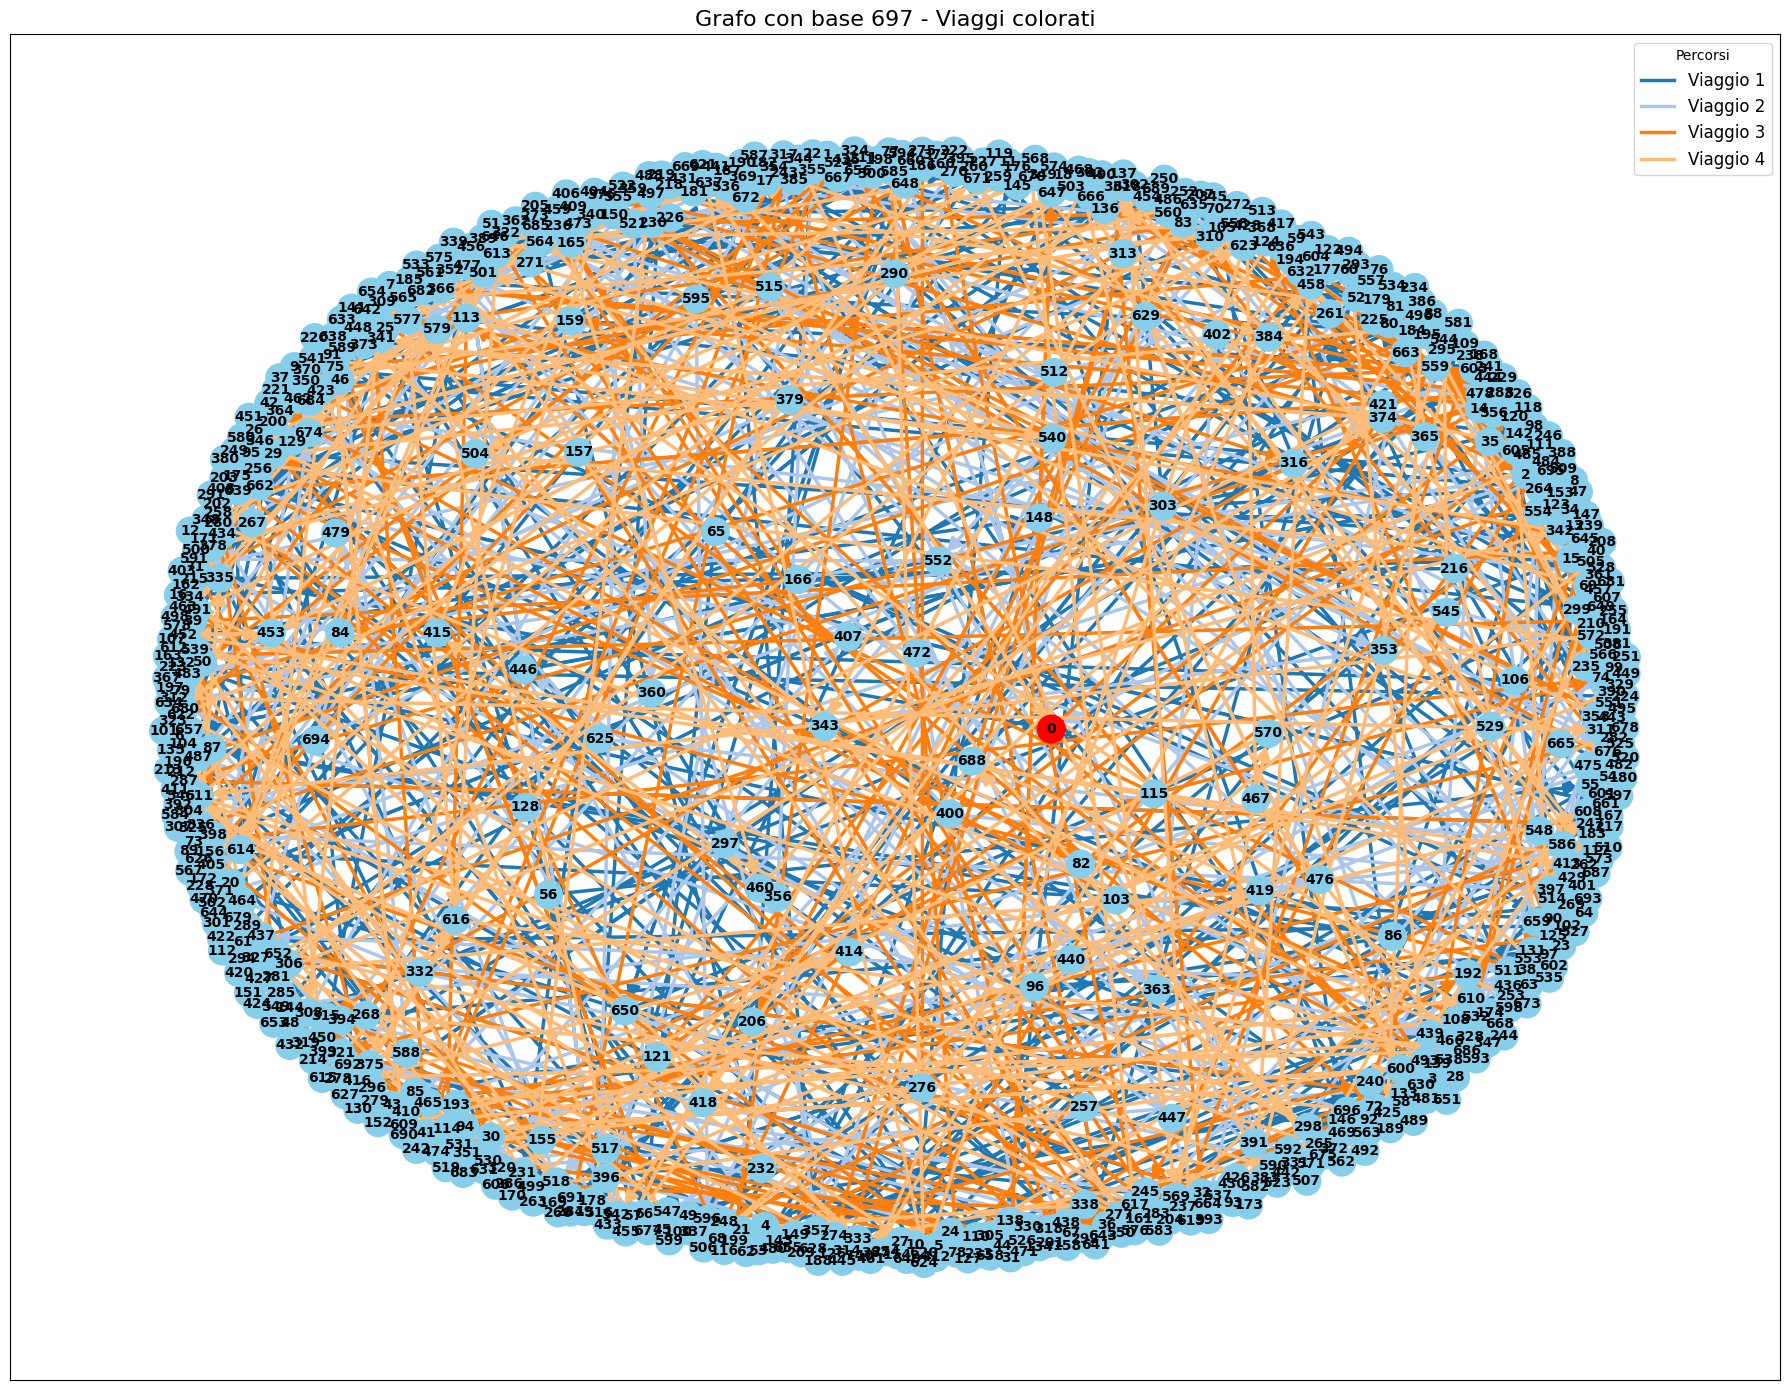

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.lines as mlines  # Import necessario per le custom legend

# creo una lista delle basi da rimuovere

remove_bases = [b for b in B if b != active_base]
# print(basi_da_rimuovere)

# creo il grafo senza le basi
G_sub = G.copy()
G_sub.remove_nodes_from(remove_bases)

plt.figure(figsize=(18, 14))

# k controlla la distanza tra i nodi
pos = nx.spring_layout(G_sub, k=2.5, iterations=100, seed=42)


node_colors = ["red" if n == active_base else "skyblue" for n in G_sub.nodes()]

# 0 se è la base altrimenti i valore del nodo
labels = {n: (0 if n == active_base else n) for n in G_sub.nodes()}

# Estrai gli archi dai path
path_edges = [[] for _ in all_paths]  # lista di archi per ogni path



# Usa tab20 se ci sono pochi percorsi, altrimenti usa hsv per averne di più
if len(all_paths) <= 20:
    cmap = matplotlib.colormaps['tab20']
    colors_path = [cmap(i/20) for i in range(len(all_paths))]
else:
    cmap = matplotlib.colormaps['hsv']
    colors_path = [cmap(i/len(all_paths)) for i in range(len(all_paths))]

for idx, path in enumerate(all_paths):

    # all_paths contiene già liste di interi
    # creo coppie di archi
    for i in range(len(path) - 1):
        path_edges[idx].append((path[i], path[i + 1]))

# disegno i nodi
nx.draw_networkx_nodes(G_sub, pos, node_size=400, node_color=node_colors)
nx.draw_networkx_labels(G_sub, pos,labels=labels, font_size=10, font_weight="bold")

# Crea una lista per gli handle della legenda
legend_handles = []

# archi dei path
for idx, edges in enumerate(path_edges):
    if not edges: continue # Salta path vuoti
    
    # Aggiungi handle manuale per la legenda
    line = mlines.Line2D([], [], color=colors_path[idx], linewidth=2.5, label=f"Viaggio {idx+1}")
    legend_handles.append(line)
    
    nx.draw_networkx_edges(
        G_sub,
        pos,
        edgelist=edges,
        edge_color=[colors_path[idx]],
        arrows=True,
        arrowsize=20,
        width=2.5,
        # label=f"Viaggio {idx+1}", # Non necessario se usiamo handles custom
    )

plt.title(f"Grafo con base {active_base} - Viaggi colorati", fontsize=16)
# Passa esplicitamente gli handle alla legenda
plt.legend(handles=legend_handles, fontsize=12, loc='best', title="Percorsi")
plt.tight_layout()
plt.show()
